<a href="https://colab.research.google.com/github/rajsuprio/sms_spam_svm/blob/main/SMS_Spam_SVM_raj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SMS Spam Classification using SVM
Dataset: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset?resource=download

In [1]:
# Install (if needed)
!pip -q install wordcloud nltk scikit-learn


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
import re, string, nltk
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,classification_report,
confusion_matrix,ConfusionMatrixDisplay,
precision_score,recall_score,f1_score,roc_curve,auc)

nltk.download('stopwords')
nltk.download('wordnet')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


## Upload dataset (`spam.csv`) downloaded from Kaggle.

In [3]:
from google.colab import files
uploaded = files.upload()

Saving spam.csv to spam.csv


In [4]:
df = pd.read_csv("spam.csv", encoding="latin-1")

df = df[['v1', 'v2']]

df.columns = ['label', 'message']

In [5]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:",df.duplicated().sum())
print(df['label'].value_counts())


(5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


## Exploratory Data Analysis

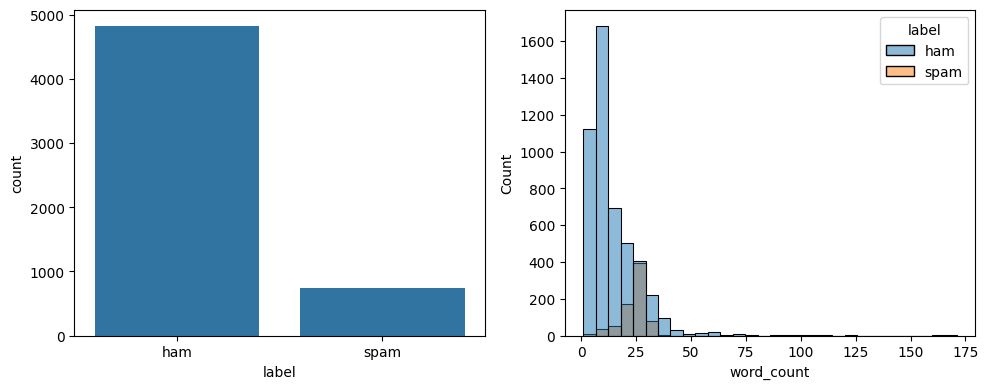

In [6]:
df['char_count']=df['message'].str.len()
df['word_count']=df['message'].str.split().str.len()

fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.countplot(data=df,x='label',ax=ax[0])
sns.histplot(data=df,x='word_count',hue='label',bins=30,ax=ax[1])
plt.tight_layout()
plt.show()




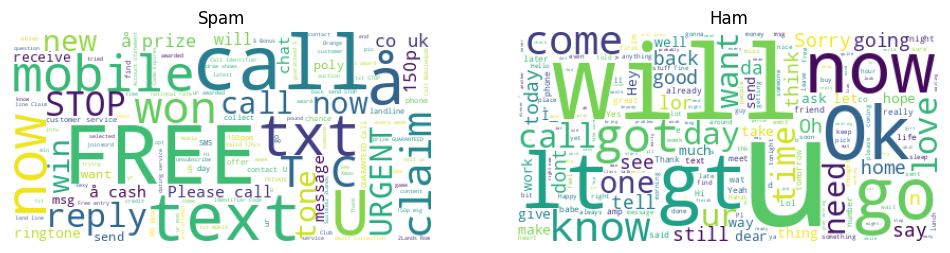

In [7]:
spam=' '.join(df[df.label=='spam'].message)
ham=' '.join(df[df.label=='ham'].message)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(WordCloud(background_color='white').generate(spam))
plt.axis('off'); plt.title("Spam")
plt.subplot(1,2,2)
plt.imshow(WordCloud(background_color='white').generate(ham))
plt.axis('off'); plt.title("Ham")
plt.show()


## Preprocessing

In [8]:
# Load the list of English stopwords (e.g., "the", "is", "and")
stop_words = set(stopwords.words('english'))

# Create a WordNet lemmatizer object to convert words to their base form
lemm = WordNetLemmatizer()

# Define a function to clean and preprocess SMS text
def clean_text(text):

    # Convert all characters to lowercase
    text = text.lower()

    # Remove URLs (e.g., http://example.com or www.example.com)
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove email addresses (e.g., abc@gmail.com)
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove all numeric digits from the text
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation marks such as !, ?, ., ,, :, etc.
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Split the sentence into words,
    # remove stopwords,
    # and convert each word to its base (lemma) form
    tokens = [
        lemm.lemmatize(word)
        for word in text.split()
        if word not in stop_words
    ]

    # Join the cleaned words back into a single string
    return ' '.join(tokens)

# Remove duplicate SMS messages from the dataset
df = df.drop_duplicates()

# Apply the clean_text() function to every message
# and store the cleaned text in a new column named 'clean_message'
df['clean_message'] = df['message'].apply(clean_text)

# Convert categorical labels into numerical values
# ham  -> 0
# spam -> 1
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

# Display the first five rows of the processed dataset
df.head()

,label,message,char_count,word_count,clean_message
0,0,"Go until jurong point, crazy.. Available only ...",111,20,go jurong point crazy available bugis n great ...
1,0,Ok lar... Joking wif u oni...,29,6,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,free entry wkly comp win fa cup final tkts st ...
3,0,U dun say so early hor... U c already then say...,49,11,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,13,nah dont think go usf life around though


## Train/Test Split

In [9]:
from sklearn.model_selection import train_test_split

X = df['clean_message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)


(4135,)
(1034,)


## SVM Model

In [10]:
pipeline=Pipeline([
('tfidf',TfidfVectorizer(max_features=5000,ngram_range=(1,2))),
('svm',LinearSVC())
])

pipeline.fit(X_train,y_train)
pred=pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test,pred))
print("Precision:",precision_score(y_test,pred))
print("Recall:",recall_score(y_test,pred))
print("F1:",f1_score(y_test,pred))
print(classification_report(y_test,pred))




Accuracy: 0.9835589941972921
Precision: 0.9830508474576272
Recall: 0.8854961832061069
F1: 0.9317269076305221
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       903
           1       0.98      0.89      0.93       131

    accuracy                           0.98      1034
   macro avg       0.98      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



## Hyperparameter Tuning

In [11]:
param_grid={
'svm__C':[0.1,1,10]
}
grid=GridSearchCV(pipeline,param_grid,cv=5,n_jobs=-1)
grid.fit(X_train,y_train)

print("Best Parameters:",grid.best_params_)
print("Best CV Score:",grid.best_score_)


Best Parameters: {'svm__C': 1}
Best CV Score: 0.9787182587666263


## Cross Validation

In [12]:
scores=cross_val_score(grid.best_estimator_,df['clean_message'],df['label'],cv=5)
print(scores)
print("Mean Accuracy:",scores.mean())


[0.97969052 0.9787234  0.97969052 0.9787234  0.97483059]
Mean Accuracy: 0.9783316887022269


## Prediction Function

In [13]:
model=grid.best_estimator_

def predict_sms(text):
    pred=model.predict([clean_text(text)])[0]
    return "Spam" if pred==1 else "Ham"

print(predict_sms("Congratulations! You have won a free iPhone. Click here now."))
print(predict_sms("Hi, are we meeting tomorrow at 3 PM?"))


Spam
Ham


### Additional Feature Engineering

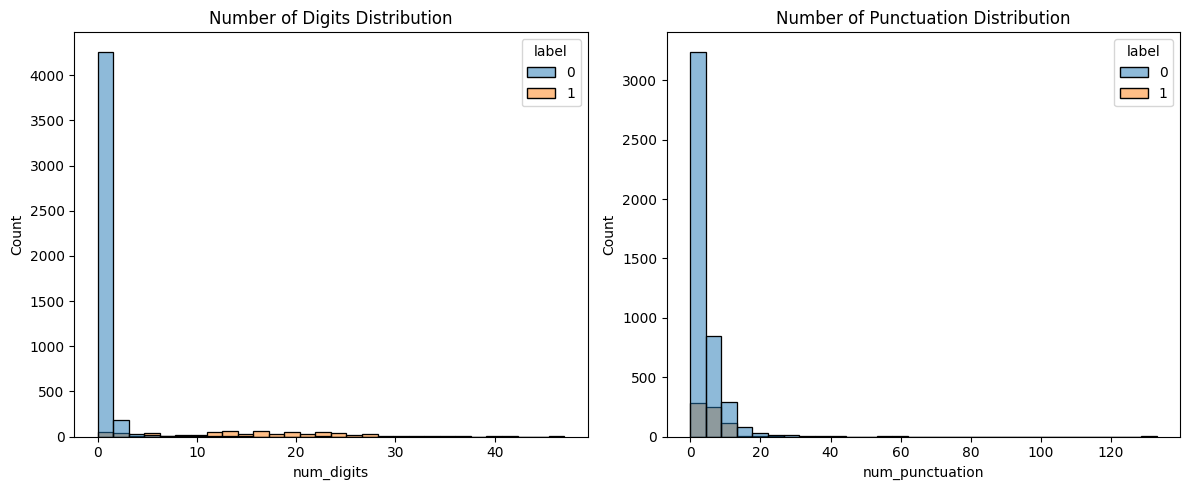

In [17]:
import string

# Create the features before plotting
df['num_digits'] = df['message'].apply(lambda x: sum(c.isdigit() for c in x))
df['num_punctuation'] = df['message'].apply(lambda x: sum(c in string.punctuation for c in x))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x='num_digits', hue='label', bins=30, ax=ax[0])
ax[0].set_title('Number of Digits Distribution')

sns.histplot(data=df, x='num_punctuation', hue='label', bins=30, ax=ax[1])
ax[1].set_title('Number of Punctuation Distribution')

plt.tight_layout()
plt.show()

In [18]:
df['num_digits'] = df['message'].apply(lambda x: sum(c.isdigit() for c in x))
df['num_punctuation'] = df['message'].apply(lambda x: sum(c in string.punctuation for c in x))

print(df.head())

   label                                            message  char_count  \
0      0  Go until jurong point, crazy.. Available only ...         111   
1      0                      Ok lar... Joking wif u oni...          29   
2      1  Free entry in 2 a wkly comp to win FA Cup fina...         155   
3      0  U dun say so early hor... U c already then say...          49   
4      0  Nah I don't think he goes to usf, he lives aro...          61   

   word_count                                      clean_message  num_digits  \
0          20  go jurong point crazy available bugis n great ...           0   
1           6                            ok lar joking wif u oni           0   
2          28  free entry wkly comp win fa cup final tkts st ...          25   
3          11                u dun say early hor u c already say           0   
4          13           nah dont think go usf life around though           0   

   num_punctuation  
0                9  
1                6  
2    

In [19]:
import string

# 1. Count of uppercase characters
df['uppercase_count'] = df['message'].apply(lambda x: sum(1 for c in x if c.isupper()))

# 2. Ratio of uppercase characters to total characters
df['uppercase_ratio'] = df['uppercase_count'] / (df['char_count'] + 1)

# 3. Average word length
def get_avg_word_len(text):
    words = text.split()
    if len(words) == 0:
        return 0
    return sum(len(word) for word in words) / len(words)

df['avg_word_len'] = df['message'].apply(get_avg_word_len)

# 4. Check presence of currency symbols common in spam (e.g. $, £, €)
df['contains_currency'] = df['message'].apply(lambda x: int(any(sym in x for sym in ['$', '£', '€'])))

# Display the new features along with labels
display(df[['message', 'label', 'uppercase_count', 'uppercase_ratio', 'avg_word_len', 'contains_currency']].head())


,message,label,uppercase_count,uppercase_ratio,avg_word_len,contains_currency
0,"Go until jurong point, crazy.. Available only ...",0,3,0.026786,4.600000,0
1,Ok lar... Joking wif u oni...,0,2,0.066667,4.000000,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,10,0.064103,4.571429,0
3,U dun say so early hor... U c already then say...,0,2,0.040000,3.545455,0
4,"Nah I don't think he goes to usf, he lives aro...",0,2,0.032258,3.769231,0


/tmp/ipykernel_1252/2350933059.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y='uppercase_count', ax=axes[0, 0], palette='pastel')
/tmp/ipykernel_1252/2350933059.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y='uppercase_ratio', ax=axes[0, 1], palette='pastel')
/tmp/ipykernel_1252/2350933059.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y='avg_word_len', ax=axes[1, 0], palette='pastel')


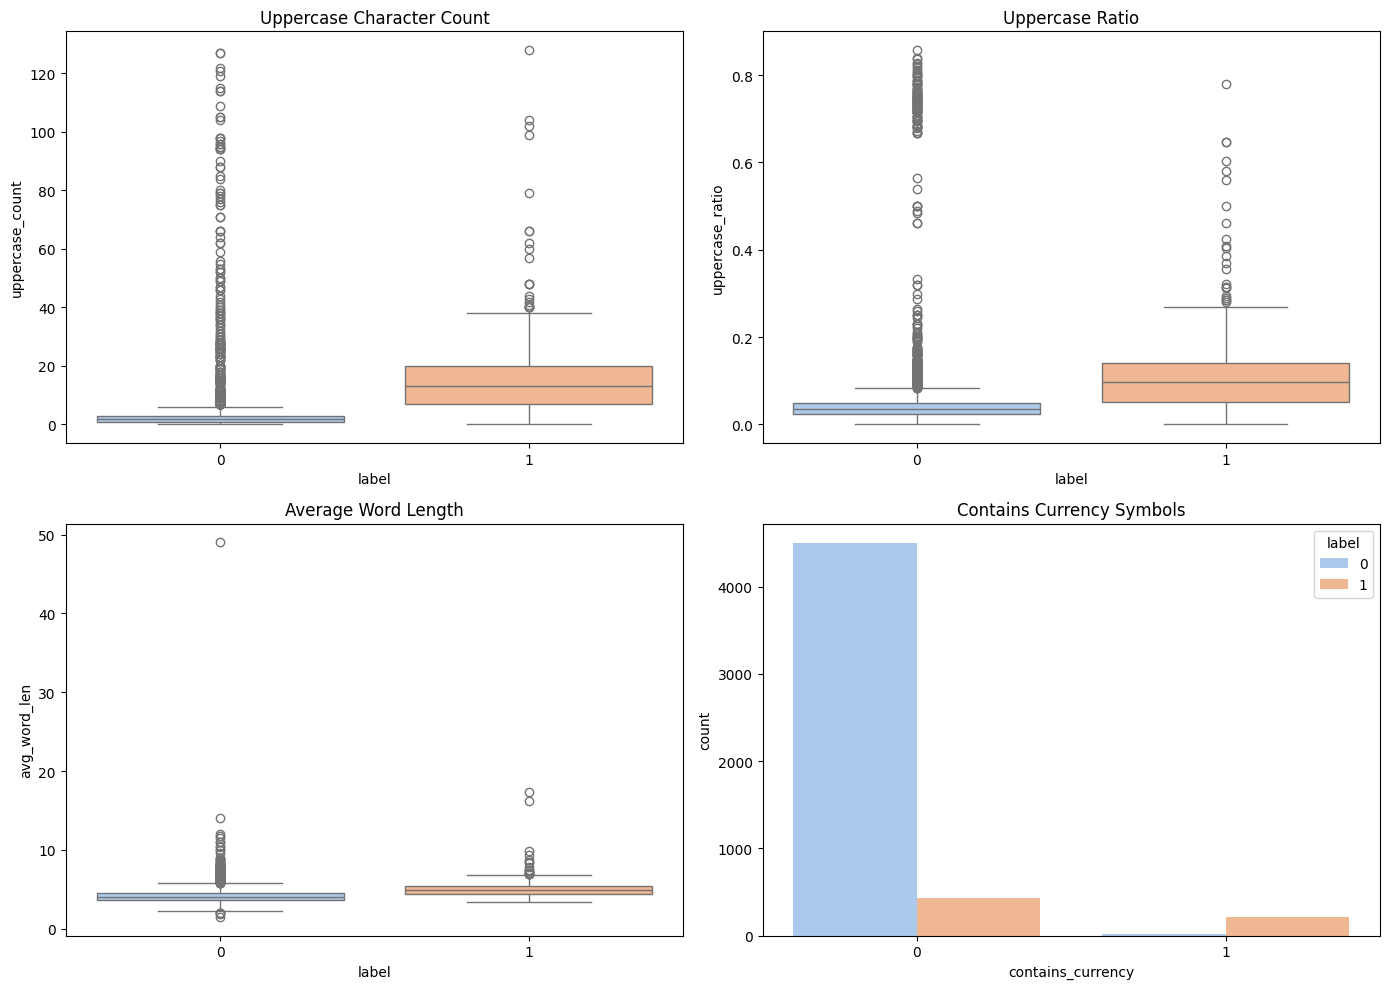

In [20]:
# Visualize the new features to see if they differentiate spam (1) from ham (0)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df, x='label', y='uppercase_count', ax=axes[0, 0], palette='pastel')
axes[0, 0].set_title('Uppercase Character Count')

sns.boxplot(data=df, x='label', y='uppercase_ratio', ax=axes[0, 1], palette='pastel')
axes[0, 1].set_title('Uppercase Ratio')

sns.boxplot(data=df, x='label', y='avg_word_len', ax=axes[1, 0], palette='pastel')
axes[1, 0].set_title('Average Word Length')

sns.countplot(data=df, x='contains_currency', hue='label', ax=axes[1, 1], palette='pastel')
axes[1, 1].set_title('Contains Currency Symbols')

plt.tight_layout()
plt.show()

In [21]:
# 5. Digit Ratio (proportion of characters that are numbers)
df['digit_ratio'] = df['num_digits'] / (df['char_count'] + 1)

# 6. Flag for common high-frequency spam words
spam_words = ['free', 'claim', 'winner', 'txt', 'urgent', 'prize', 'stop', 'reply', 'mobile', 'call']
def check_spam_keywords(text):
    text_lower = text.lower()
    return int(any(word in text_lower for word in spam_words))

df['contains_spam_keywords'] = df['message'].apply(check_spam_keywords)

# Display updated dataframe containing the newest features
display(df[['message', 'label', 'digit_ratio', 'contains_spam_keywords']].head())

,message,label,digit_ratio,contains_spam_keywords
0,"Go until jurong point, crazy.. Available only ...",0,0.000000,0
1,Ok lar... Joking wif u oni...,0,0.000000,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,0.160256,1
3,U dun say so early hor... U c already then say...,0,0.000000,0
4,"Nah I don't think he goes to usf, he lives aro...",0,0.000000,0


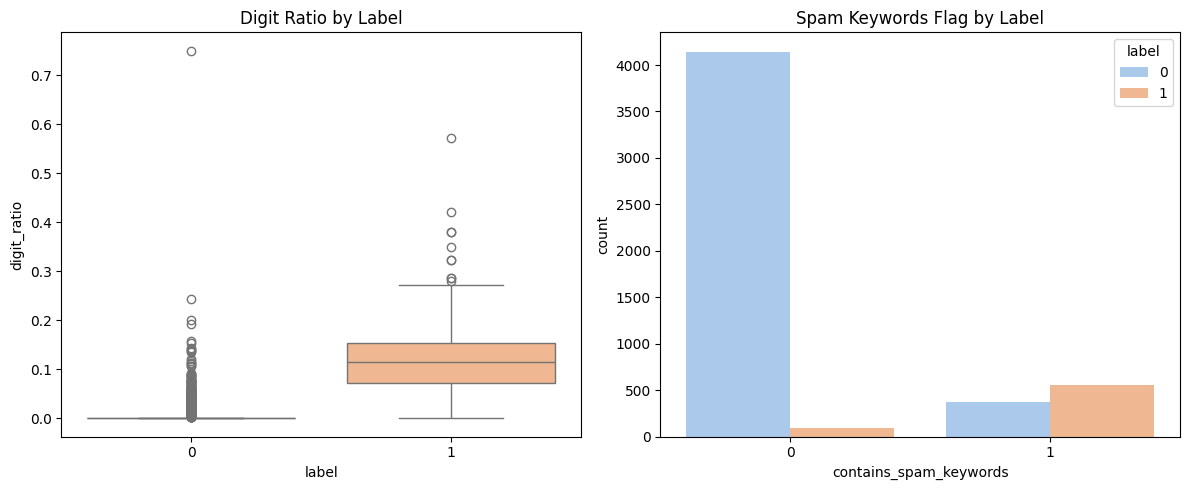

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x='label', y='digit_ratio', ax=axes[0], hue='label', palette='pastel', legend=False)
axes[0].set_title('Digit Ratio by Label')

sns.countplot(data=df, x='contains_spam_keywords', hue='label', ax=axes[1], palette='pastel')
axes[1].set_title('Spam Keywords Flag by Label')

plt.tight_layout()
plt.show()

In [23]:
# 5. Digit Ratio (proportion of characters that are numbers)
df['digit_ratio'] = df['num_digits'] / (df['char_count'] + 1)

# 6. Flag for common high-frequency spam words
spam_words = ['free', 'claim', 'winner', 'txt', 'urgent', 'prize', 'stop', 'reply', 'mobile', 'call']
def check_spam_keywords(text):
    text_lower = text.lower()
    return int(any(word in text_lower for word in spam_words))

df['contains_spam_keywords'] = df['message'].apply(check_spam_keywords)

# Display updated dataframe containing the newest features
display(df[['message', 'label', 'digit_ratio', 'contains_spam_keywords']].head())

,message,label,digit_ratio,contains_spam_keywords
0,"Go until jurong point, crazy.. Available only ...",0,0.000000,0
1,Ok lar... Joking wif u oni...,0,0.000000,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,0.160256,1
3,U dun say so early hor... U c already then say...,0,0.000000,0
4,"Nah I don't think he goes to usf, he lives aro...",0,0.000000,0


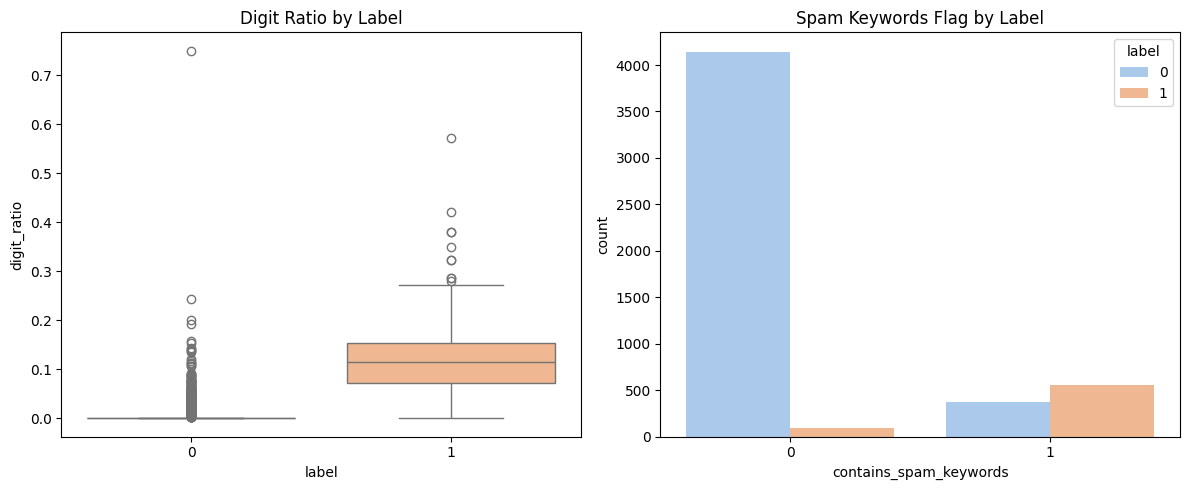

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x='label', y='digit_ratio', ax=axes[0], hue='label', palette='pastel', legend=False)
axes[0].set_title('Digit Ratio by Label')

sns.countplot(data=df, x='contains_spam_keywords', hue='label', ax=axes[1], palette='pastel')
axes[1].set_title('Spam Keywords Flag by Label')

plt.tight_layout()
plt.show()

In [25]:
# 7. Character-to-Word Count Ratio
df['char_to_word_ratio'] = df['char_count'] / (df['word_count'] + 1)

# 8. Excessive Punctuation Indicator (e.g., repeating exclamation points, question marks, or multiple punctuation marks together)
def check_excessive_punctuation(text):
    # Checks for occurrences of !!, ???, or similar consecutive punctuation marks
    return int(bool(re.search(r'[!?]{2,}', text)))

df['excessive_punctuation'] = df['message'].apply(check_excessive_punctuation)

# 9. Starts with a high-priority action word (e.g. Call, Win, Free, Get)
action_verbs = ['call', 'win', 'free', 'get', 'claim', 'urgent', 'go']
def starts_with_action(text):
    first_word = text.strip().split()[0].lower() if text.strip() else ''
    # Remove punctuation from first word
    first_word = first_word.translate(str.maketrans('', '', string.punctuation))
    return int(first_word in action_verbs)

df['starts_with_action'] = df['message'].apply(starts_with_action)

# Display the newly engineered features
display(df[['message', 'label', 'char_to_word_ratio', 'excessive_punctuation', 'starts_with_action']].head())

,message,label,char_to_word_ratio,excessive_punctuation,starts_with_action
0,"Go until jurong point, crazy.. Available only ...",0,5.285714,0,1
1,Ok lar... Joking wif u oni...,0,4.142857,0,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,5.344828,0,1
3,U dun say so early hor... U c already then say...,0,4.083333,0,0
4,"Nah I don't think he goes to usf, he lives aro...",0,4.357143,0,0


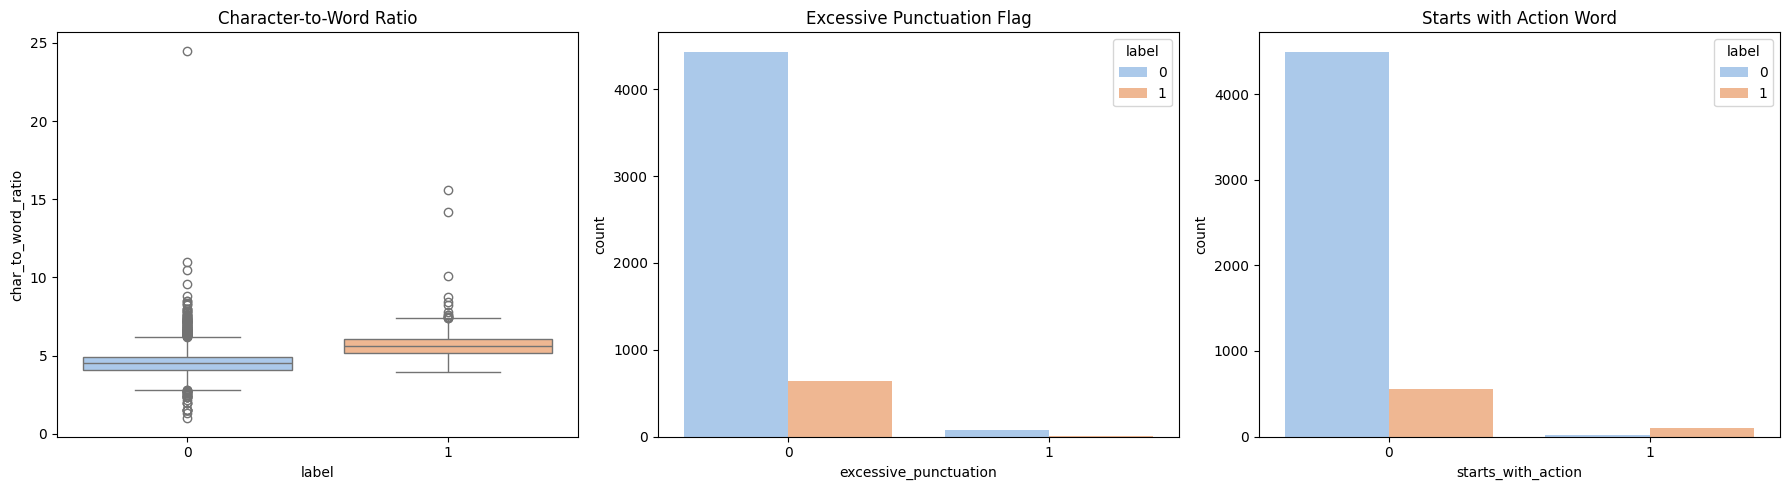

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x='label', y='char_to_word_ratio', ax=axes[0], hue='label', palette='pastel', legend=False)
axes[0].set_title('Character-to-Word Ratio')

sns.countplot(data=df, x='excessive_punctuation', hue='label', ax=axes[1], palette='pastel')
axes[1].set_title('Excessive Punctuation Flag')

sns.countplot(data=df, x='starts_with_action', hue='label', ax=axes[2], palette='pastel')
axes[2].set_title('Starts with Action Word')

plt.tight_layout()
plt.show()

In [27]:
# 10. Contains phone number pattern (typically 7 to 11 digits in sequence, sometimes with spaces/dashes)
def detect_phone_number(text):
    # Search for sequence of 7 or more digits
    return int(bool(re.search(r'\b\d{7,12}\b', text)))

df['contains_phone_number'] = df['message'].apply(detect_phone_number)

# 11. Check if the message is completely in ALL CAPS (excluding punctuation/numbers)
def check_all_caps(text):
    letters = [c for c in text if c.isalpha()]
    if len(letters) < 3:
        return 0
    return int(all(c.isupper() for c in letters))

df['is_all_caps'] = df['message'].apply(check_all_caps)

# 12. Contains offer indicators like %, off, save, promo, discount
offer_words = ['%', 'off', 'save', 'promo', 'discount', 'deal', 'cashback']
def check_offers(text):
    text_lower = text.lower()
    return int(any(word in text_lower for word in offer_words))

df['contains_offers'] = df['message'].apply(check_offers)

# Display the new features
display(df[['message', 'label', 'contains_phone_number', 'is_all_caps', 'contains_offers']].head())

,message,label,contains_phone_number,is_all_caps,contains_offers
0,"Go until jurong point, crazy.. Available only ...",0,0,0,0
1,Ok lar... Joking wif u oni...,0,0,0,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,0,0,0
3,U dun say so early hor... U c already then say...,0,0,0,0
4,"Nah I don't think he goes to usf, he lives aro...",0,0,0,0


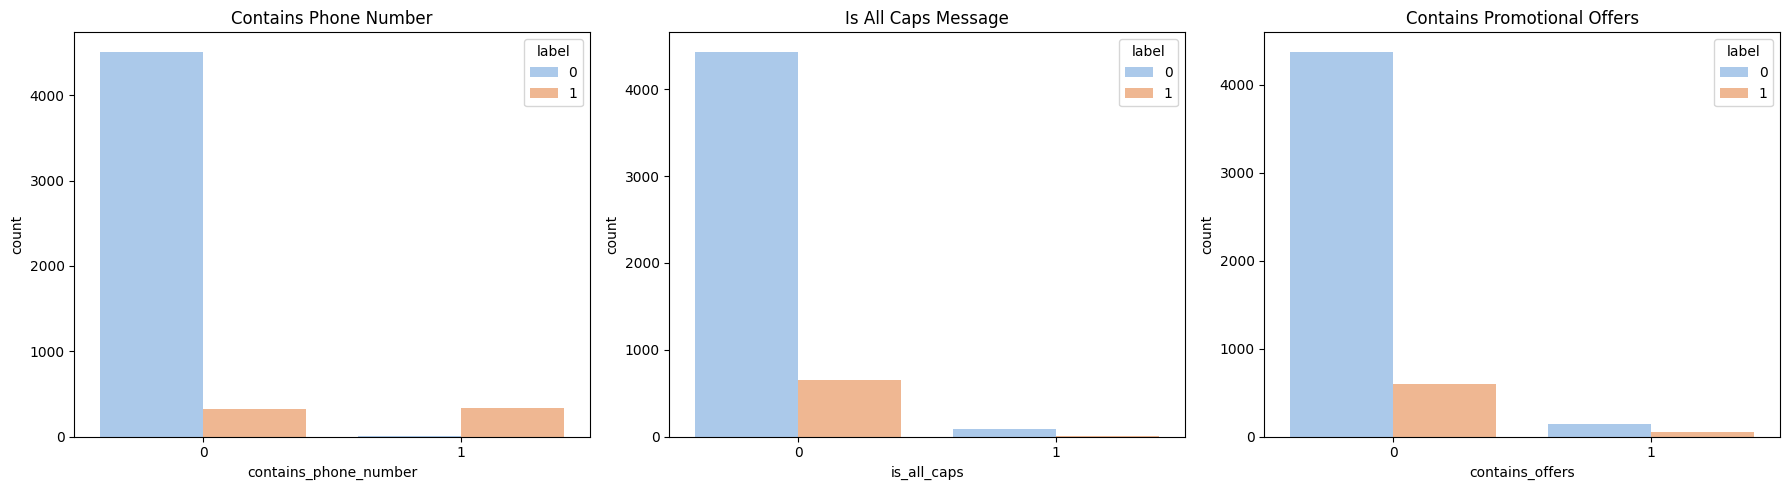

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df, x='contains_phone_number', hue='label', ax=axes[0], palette='pastel')
axes[0].set_title('Contains Phone Number')

sns.countplot(data=df, x='is_all_caps', hue='label', ax=axes[1], palette='pastel')
axes[1].set_title('Is All Caps Message')

sns.countplot(data=df, x='contains_offers', hue='label', ax=axes[2], palette='pastel')
axes[2].set_title('Contains Promotional Offers')

plt.tight_layout()
plt.show()

In [29]:
# 13. Check if message contains an email address
def detect_email(text):
    return int(bool(re.search(r'\S+@\S+', text)))

df['contains_email'] = df['message'].apply(detect_email)

# 14. Check if message contains a URL, link, or common web domain patterns in raw text
def detect_url(text):
    return int(bool(re.search(r'http\S+|www\S+|\.co\.uk|\.com|\.net|\.tk|\.org', text, re.IGNORECASE)))

df['contains_url_pattern'] = df['message'].apply(detect_url)

# Display the new features
display(df[['message', 'label', 'contains_email', 'contains_url_pattern']].head())

,message,label,contains_email,contains_url_pattern
0,"Go until jurong point, crazy.. Available only ...",0,0,0
1,Ok lar... Joking wif u oni...,0,0,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,1,0,0
3,U dun say so early hor... U c already then say...,0,0,0
4,"Nah I don't think he goes to usf, he lives aro...",0,0,0


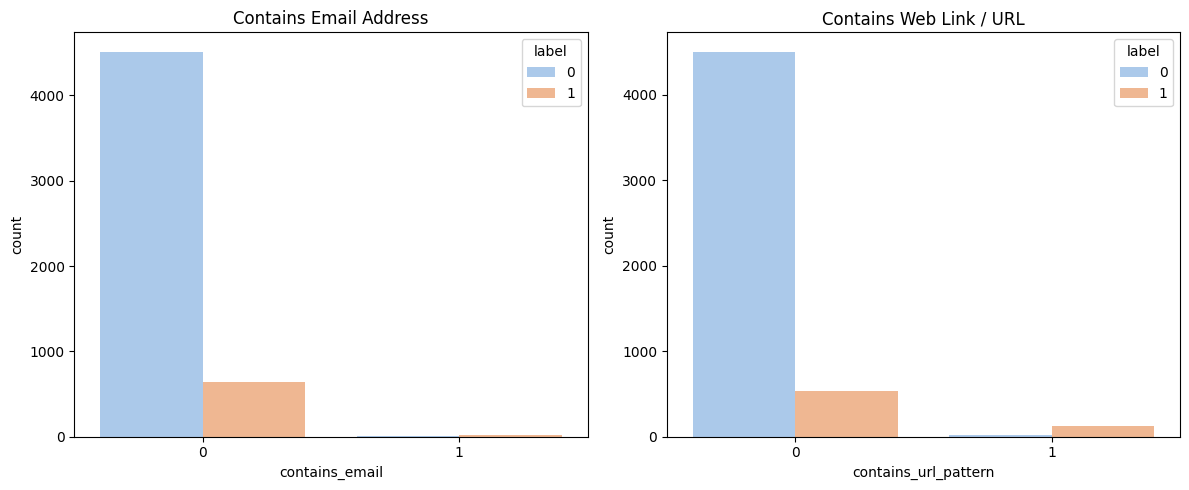

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x='contains_email', hue='label', ax=axes[0], palette='pastel')
axes[0].set_title('Contains Email Address')

sns.countplot(data=df, x='contains_url_pattern', hue='label', ax=axes[1], palette='pastel')
axes[1].set_title('Contains Web Link / URL')

plt.tight_layout()
plt.show()